## 나의 입출금 시스템

** 완성 결과 ** 
- 전체 수입·지출·남은 금액
- 항목별 지출 순위 / 어디에 많이 썼는지 확인
- 월별 수입·지출·남은 금액 표
- 항목별 지출 그래프 1개와 CSV 결과 2개(월별요약, 항목별지출)

## 0. 환경 설정 및 실행 준비

In [1]:
import pandas as pd                    # 표 데이터
import matplotlib.pyplot as plt        # 그래프 (항목별 지출 그래프 그릴 때 사용 예정)
from pathlib import Path               # 폴더/파일 경로 다루기
from IPython.display import display    # 표를 표 모양으로 출력 (셀 중간에서도)

# 산출물 저장 폴더 지정
OUTPUT = Path('outputs')
OUTPUT.mkdir(exist_ok=True)            # 없으면 만들고, 이미 있으면 넘어감 (다시 실행해도 에러 X)

## 1. 데이터
* 한 줄은 거래 내역 한 건
* 금액 단위는 원
* 금액은 항상 양수이고 구분으로 수입과 지출을 나눔
* 수입 : 월급, 지출 : 월세·식비·교통·쇼핑·통신
* 리얼 통장에는 환불, 이체, 카드대금 중복 등이 올 수 있음

In [2]:
# 거래 내역 한 건 = [날짜, 구분, 항목, 금액] / 한 달 6건 x 3개월 = 18건
data = [
    ['2026-01-01', '수입', '월급', 2000000],
    ['2026-01-05', '지출', '월세', 600000],
    ['2026-01-10', '지출', '식비', 280000],
    ['2026-01-15', '지출', '교통', 70000],
    ['2026-01-20', '지출', '쇼핑', 150000],
    ['2026-01-25', '지출', '통신', 100000],
    ['2026-02-01', '수입', '월급', 2000000],
    ['2026-02-05', '지출', '월세', 600000],
    ['2026-02-10', '지출', '식비', 320000],
    ['2026-02-15', '지출', '교통', 80000],
    ['2026-02-20', '지출', '쇼핑', 300000],
    ['2026-02-25', '지출', '통신', 120000],
    ['2026-03-01', '수입', '월급', 2000000],
    ['2026-03-05', '지출', '월세', 600000],
    ['2026-03-10', '지출', '식비', 250000],
    ['2026-03-15', '지출', '교통', 60000],
    ['2026-03-20', '지출', '쇼핑', 100000],
    ['2026-03-25', '지출', '통신', 80000],
]

In [3]:
# 컬럼명 : '날짜', '구분', '항목', '금액'
# 리스트의 리스트로 만들 땐 columns 로 열 이름을 따로 지정
# 날짜는 아직 글자(str) → 월별 계산할 땐 pd.to_datetime 또는 str[:7] 필요
df = pd.DataFrame(data, columns=['날짜', '구분', '항목', '금액'])
display(df)
print('내역 수:', len(df))     # 18


,날짜,구분,항목,금액
0,2026-01-01,수입,월급,2000000
1,2026-01-05,지출,월세,600000
2,2026-01-10,지출,식비,280000
3,2026-01-15,지출,교통,70000
4,2026-01-20,지출,쇼핑,150000
5,2026-01-25,지출,통신,100000
6,2026-02-01,수입,월급,2000000
7,2026-02-05,지출,월세,600000
8,2026-02-10,지출,식비,320000
9,2026-02-15,지출,교통,80000


내역 수: 18


* 데이터를 보고 1월 월급과 월세가 어느 행에 있는지 확인
* 수입과 지출이 몇건인가?

In [4]:
display(df.head())  # 처음 5행
print(df['구분'].value_counts())  # 수입 3건, 지출 15건
print('빠진 값:', df.isna().sum().sum())   # 열별 NaN 개수 → 한 번 더 sum 해서 전체 NaN 개수

,날짜,구분,항목,금액
0,2026-01-01,수입,월급,2000000
1,2026-01-05,지출,월세,600000
2,2026-01-10,지출,식비,280000
3,2026-01-15,지출,교통,70000
4,2026-01-20,지출,쇼핑,150000


구분
지출    15
수입     3
Name: count, dtype: int64
빠진 값: 0


## 2. 수입과 지출 구분 : 마스크 연산 필터링

In [5]:
# 마스크 : 구분이 '수입' / '지출' 인 행만 True
# .copy() : 다음에 '표시' 열을 추가할 때 SettingWithCopyWarning 안 나게 복사본으로 만듦
income = df[df['구분'] == '수입'].copy()
expenses = df[df['구분'] == '지출'].copy()

display(income)             # 3행 (인덱스는 원래 번호 0, 6, 12 그대로)
display(expenses.head())    # 15행 중 앞 5행

,날짜,구분,항목,금액
0,2026-01-01,수입,월급,2000000
6,2026-02-01,수입,월급,2000000
12,2026-03-01,수입,월급,2000000


,날짜,구분,항목,금액
1,2026-01-05,지출,월세,600000
2,2026-01-10,지출,식비,280000
3,2026-01-15,지출,교통,70000
4,2026-01-20,지출,쇼핑,150000
5,2026-01-25,지출,통신,100000


* 전체 수입, 전체 지출, 남은 금액 구하기

In [6]:
total_income = income['금액'].sum()          # 6,000,000
total_expense = expenses['금액'].sum()       # 3,710,000
remaining = total_income - total_expense     # 2,290,000 (수입의 약 38%)

# {값:,} → 천 단위 쉼표
print(f'전체 수입: {total_income:,}원')
print(f'전체 지출: {total_expense:,}원')
print(f'남은 금액: {remaining:,}원')

전체 수입: 6,000,000원
전체 지출: 3,710,000원
남은 금액: 2,290,000원


## 3. 표시열 만들기

* 표시열을 만들어서 금액이 10만 원 이상 : 큰 지출, 그보다 작으면 '일반 지출' 표기
* apply() 사용

In [7]:
def expense_label(amount):       # 금액 1개를 받아서 라벨 1개 반환
    if amount >= 100000:         # >= 라서 딱 10만원도 '큰 지출'
        return '큰 지출'
    else:
        return '일반 지출'

# 금액을 하나씩 함수에 넣고 결과를 '표시' 열로 추가 (함수 이름만, 괄호 X)
expenses['표시'] = expenses['금액'].apply(expense_label)
display(expenses[['항목', '금액', '표시']])     # 큰 지출 12건 / 일반 지출 3건 (전부 교통)

,항목,금액,표시
1,월세,600000,큰 지출
2,식비,280000,큰 지출
3,교통,70000,일반 지출
4,쇼핑,150000,큰 지출
5,통신,100000,큰 지출
7,월세,600000,큰 지출
8,식비,320000,큰 지출
9,교통,80000,일반 지출
10,쇼핑,300000,큰 지출
11,통신,120000,큰 지출


* 큰 지출 출력 : mask, 식비/쇼핑 항목만 출력 : isin()

In [8]:
# 마스크 : 10만원 이상 (기준이 expense_label 안에도 있음 → 바꿀 땐 둘 다 수정)
big_expenses = expenses[expenses['금액'] >= 100000]
# isin : 항목이 식비 또는 쇼핑이면 True (== 두 개를 | 로 묶은 것과 같음)
food_shopping = expenses[expenses['항목'].isin(['식비', '쇼핑'])]

display(big_expenses.head())
display(food_shopping)     # 식비 3 + 쇼핑 3 = 6건

,날짜,구분,항목,금액,표시
1,2026-01-05,지출,월세,600000,큰 지출
2,2026-01-10,지출,식비,280000,큰 지출
4,2026-01-20,지출,쇼핑,150000,큰 지출
5,2026-01-25,지출,통신,100000,큰 지출
7,2026-02-05,지출,월세,600000,큰 지출


,날짜,구분,항목,금액,표시
2,2026-01-10,지출,식비,280000,큰 지출
4,2026-01-20,지출,쇼핑,150000,큰 지출
8,2026-02-10,지출,식비,320000,큰 지출
10,2026-02-20,지출,쇼핑,300000,큰 지출
14,2026-03-10,지출,식비,250000,큰 지출
16,2026-03-20,지출,쇼핑,100000,큰 지출


## 4. 항목별 지출 순위 : groupby  +  어디에 많이 썼는지 확인(sort)

In [9]:
# 항목별로 묶어서 → 금액 열만 골라 → 합계 (금액 안 고르면 글자 열까지 합쳐짐)
category_total = expenses.groupby('항목')['금액'].sum()
category_total = category_total.sort_values(ascending=False)   # 큰 금액부터 (내림차순)

display(category_total)
print('가장 큰 지출 항목:', category_total.index[0])         # 정렬했으니 0번이 1등 (이름)
print(f'해당 항목 합계: {category_total.iloc[0]:,}원')        # iloc[0] : 0번째 값

항목
월세    1800000
식비     850000
쇼핑     550000
통신     300000
교통     210000
Name: 금액, dtype: int64

가장 큰 지출 항목: 월세
해당 항목 합계: 1,800,000원


## 5. 날짜에서 월을 꺼내고 피벗 만들기

In [ ]:
# 날짜가 지금은 글자(str) → 날짜 타입으로 바꿔야 월을 꺼낼 수 있음
df['날짜'] = pd.to_datetime(df['날짜'])


# .dt.month : 날짜에서 월만 꺼내기 → 1, 2, 3
df['월'] = df['날짜'].dt.month
# =>  df['월'] = df['날짜'].str[:7] -> 날짜타입으로 안바꾼 경우

display(df.head())

# 피벗 : 행 = 월, 열 = 수입/지출, 값 = 금액 합계
monthly = pd.pivot_table(df,
                         index='월',          # 행에 올 것
                         columns='구분',      # 열에 올 것 (수입, 지출)
                         values='금액',       # 계산할 값
                         aggfunc='sum',       # 합계
                         fill_value=0)        # 빈칸은 0 으로 (수입 없는 달 대비)

# 남은 금액 = 수입 - 지출
monthly['남은금액'] = monthly['수입'] - monthly['지출']
display(monthly)



,날짜,구분,항목,금액,월
0,2026-01-01,수입,월급,2000000,1
1,2026-01-05,지출,월세,600000,1
2,2026-01-10,지출,식비,280000,1
3,2026-01-15,지출,교통,70000,1
4,2026-01-20,지출,쇼핑,150000,1


구분,수입,지출,남은금액
월,,,
1,2000000,1200000,800000
2,2000000,1420000,580000
3,2000000,1090000,910000


In [22]:
# 남은금액이 가장 큰 달을 출력
best_month = monthly['남은금액'].idxmax()            # 3
best_amount = monthly['남은금액'].max()              # 910000

best_date = df[df['월'] == best_month]['날짜'].iloc[0]   # 3월 첫 거래 날짜 → 2026-03-01

print(f'남은 금액이 가장 큰 달: {best_date:%Y-%m}')     # 2026-03
print(f'남은 금액: {best_amount:,}원')




남은 금액이 가장 큰 달: 2026-03
남은 금액: 910,000원


## 6. 지출 합계 그래프 그리기

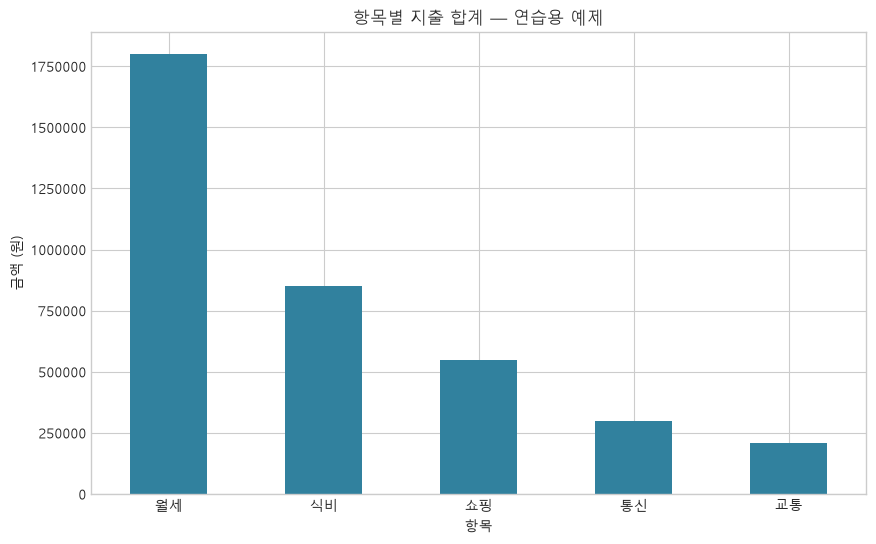

In [48]:
# 방법 1 : 맑은 고딕 직접 지정 (윈도우 전용, 맥/코랩에선 한글 깨짐)
plt.rc('font', family='Malgun Gothic')   # 윈도우 기본 글꼴이라 경로 없이 이름만
plt.rc('axes', unicode_minus=False)      # 마이너스(-) 기호 깨짐 방지

# kind='bar' : 세로 막대 / rot=0 : x축 글자 똑바로 (bar 기본은 90도로 누움)
# .plot() 은 그래프 칸(ax)을 돌려줌 → 받아 두고 아래에서 격자, 눈금 손봄
ax = category_total.plot(kind='bar', figsize=(10, 6), color='#31819e', rot=0,
                         title='항목별 지출 합계 — 연습용 예제',
                         ylabel='금액 (원)')     # x축 이름 '항목' 은 인덱스 이름이라 자동으로 나옴


ax.set_axisbelow(True)                       # 격자 뒤로
ax.grid(True)                                # 가로선만 원하면 ax.grid(True, axis='y')


ax.ticklabel_format(axis='y', style='plain')   # 1e6 줄임 끄기 → 1750000
plt.show()


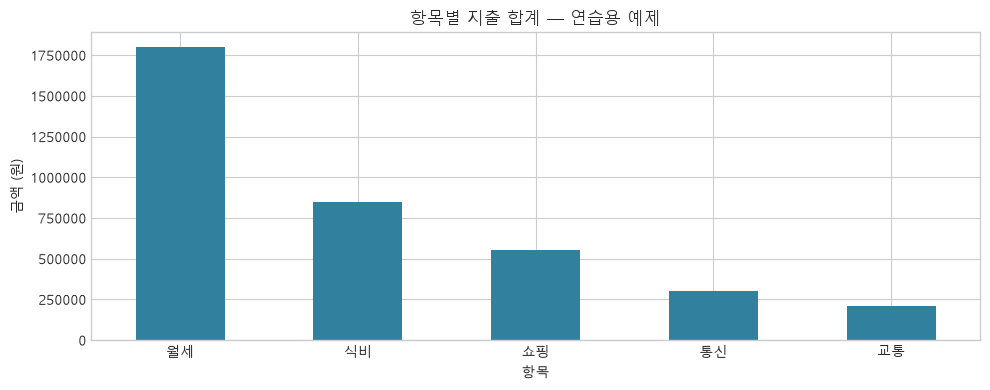

In [ ]:
# 방법 2

from matplotlib import font_manager

plt.style.use('seaborn-v0_8-whitegrid')     # 흰 배경 + 회색 격자 (격자가 원래 막대 뒤에 그려짐)
font_names = {font.name for font in font_manager.fontManager.ttflist} # set 구조, system fonts
# 후보 중 이 컴퓨터에 설치된 첫 번째 글꼴 하나 (윈도우 → 'Malgun Gothic'), 하나도 없으면 None
font = next((name for name in ['Noto Sans CJK KR', 'Noto Sans CJK JP', 'Malgun Gothic', 'AppleGothic', 'NanumGothic']
             if name in font_names), None)
plt.rcParams['font.family'] = font or 'DejaVu Sans'    # None 이면 기본 글꼴 (한글은 깨짐)
plt.rcParams['axes.unicode_minus'] = False   # -부호 깨짐 방지

# 한글 글꼴이 없을 때만 항목 이름을 영어로 바꾼 복사본 (원본 category_total 은 그대로)
plot_data = category_total.copy()
if font is None:
    plot_data.index = plot_data.index.map({
        '월세': 'Rent', '식비': 'Food', '교통': 'Transport', '쇼핑': 'Shopping', '통신': 'Phone'})

# 참고) plot_data 가 아니라 category_total 을 그리고 있음 → 영어 대체가 반영되려면 plot_data.plot(...)
ax = category_total.plot(kind='bar', figsize=(10, 4), color='#31819e', rot=0,
                         title='항목별 지출 합계 — 연습용 예제',
                         ylabel='금액 (원)')

ax.ticklabel_format(axis='y', style='plain')   # 1e6 줄임 끄기 → 1750000 (과학적 표기법)
plt.tight_layout() # 여백과 요소 사이의 간격을 자동으로 조정, 글자/축 레이어가 잘리지 않도록 하는 함수


# savefig 는 show 보다 먼저 (show 후에는 그림이 비워져서 빈 파일이 저장됨)
plt.savefig(OUTPUT / '항목별지출.png', dpi=200)  # dpi : Dots per inch : 인치당 점의 개수
plt.show()
plt.close()      # 다 쓴 그림 닫기 (다음 그래프랑 겹치지 않게)

In [52]:
# 지출합계 : 항목별지출.csv, 월별요약.scv - OUTPUT폴더에 저장

# rename('지출합계') : 시리즈 이름 '금액' → '지출합계' (CSV 열 이름이 됨)
# 인덱스(항목, 월)도 첫 열로 같이 저장됨 → 의미 있는 값이라 index=False 안 씀
category_total.rename('지출합계').to_csv(OUTPUT / '항목별지출.csv', encoding='utf-8-sig')   # utf-8-sig : 엑셀에서 한글 안 깨짐
monthly.to_csv(OUTPUT / '월별요약.csv', encoding='utf-8-sig')

print(list(OUTPUT.glob('*.csv')))    # 저장됐는지 확인
print("저장완료:", OUTPUT.resolve())   # 파일을 저장한 폴더의 절대 경로를 화면에 출력
 

[WindowsPath('outputs/월별요약.csv'), WindowsPath('outputs/항목별지출.csv')]
저장완료: C:\Project_U\01. 프로그래밍 기초\50. Project\outputs


## 미니실습

In [54]:
# 실습 1 쇼핑 내역만 선택
 # expenses에서 항목이 쇼핑인 행을 골라 shopping에 저장
shopping = expenses[expenses['항목'] == '쇼핑'].copy()
display(shopping)

,날짜,구분,항목,금액,표시
4,2026-01-20,지출,쇼핑,150000,큰 지출
10,2026-02-20,지출,쇼핑,300000,큰 지출
16,2026-03-20,지출,쇼핑,100000,큰 지출


In [55]:
if shopping is None:
    print("실습 1: 아직 작성하지 않았습니다.")
else:
    pd.testing.assert_frame_equal(shopping,expenses[expenses['항목']=='쇼핑'])
    print("실습 1 통과")

실습 1 통과


In [60]:
# 실습 2. 쇼핑 금액 더하기
# expenses에서 쇼핑 금액의 합계를 구해 shopping_total에 저장
shopping_total = expenses.loc[expenses['항목'] == '쇼핑']['금액'].sum()   # 쇼핑인 행의 금액만 → 합계
print(f'쇼핑 합계: {shopping_total:,}원')    # 550,000원

    

쇼핑 합계: 550,000원


In [64]:
# 실습 3. 20만원 이상 표시
# apply를 사용해 20만 원 이상은 '확인', 미만은 '통과'로 표시한 Series를 review에 저장
review = expenses['금액'].apply(lambda x: '확인' if x >= 200000 else '통과')
print(review)    # 확인 7, 통과 8
print(review.value_counts())

1     확인
2     확인
3     통과
4     통과
5     통과
7     확인
8     확인
9     통과
10    확인
11    통과
13    확인
14    확인
15    통과
16    통과
17    통과
Name: 금액, dtype: str
금액
통과    8
확인    7
Name: count, dtype: int64


In [69]:
# 실습 5. 남은 비율 계산
# 월별(남은금액 / 수입) x 100을 계산해 Series remaining_percent에 저장
# 힌트 : monthly 변수 사용

remaining_percent = (monthly['남은금액'] / monthly['수입']) * 100
remaining_percent

월
1    40.0
2    29.0
3    45.5
dtype: float64

In [71]:
# 실습 6. 월별 파일을 하나로 붙이기(concat) : df로 처리
jan = df[df['월'] == 1]      # 1월 파일이라고 생각
feb = df[df['월'] == 2]      # 2월
mar = df[df['월'] == 3]      # 3월

all_months = pd.concat([jan, feb, mar], ignore_index=True)   # 위아래로 이어 붙이고 인덱스 0부터 다시
display(all_months)
print('내역 수:', len(all_months))    # 6 + 6 + 6 = 18

 

,날짜,구분,항목,금액,월
0,2026-01-01,수입,월급,2000000,1
1,2026-01-05,지출,월세,600000,1
2,2026-01-10,지출,식비,280000,1
3,2026-01-15,지출,교통,70000,1
4,2026-01-20,지출,쇼핑,150000,1
5,2026-01-25,지출,통신,100000,1
6,2026-02-01,수입,월급,2000000,2
7,2026-02-05,지출,월세,600000,2
8,2026-02-10,지출,식비,320000,2
9,2026-02-15,지출,교통,80000,2


내역 수: 18


In [ ]:
# 실습 7. 월별 목표와 비교하기 : merge
# 월마다 70만 원을 남기는 목표. 목표 표를 월 기준으로 합치고 차이 계산
goal = pd.DataFrame({'월': [1, 2, 3], '목표금액': 700000})     # 목표 표 (목표 값 하나만 주면 모든 행에 들어감)


'''
= validate
one_to_one : 양쪽 모두 기준 열의 값이 고유해야 함 / 월별 실적 + 월별 목표(
one_to_many : 왼쪽은 고유하고 오른쪽은 중복 가능  / 종목정보 + 여러 계좌 보유 내역(기준정보 한 행에 여러 보유 내역 연결)
many_to_one : 왼쪽은 중복 가능하고 오른쪽은 고유  / 여러 거래 내역 + 종목별 기준정보(여러 거래가 하나의 종목정보를 참조)
many_to_many : 양쪽 중복 가능  / 양쪽에 중복이 있는 상세 거래 데이터 (다대다 병합 허용)
'''

compare = pd.merge(monthly, goal, on='월')   # 월이 인덱스라서 열로 꺼낸 뒤 월끼리 짝 맞춤
compare['차이'] = compare['남은금액'] - compare['목표금액']    # 음수 = 목표 못 채움
display(compare[['월','남은금액','목표금액','차이']])



,월,남은금액,목표금액,차이
0,1,800000,700000,100000
1,2,580000,700000,-120000
2,3,910000,700000,210000
